In [1]:
# --- Setup (works locally and in Google Colab) ---
import sys, os
from pathlib import Path
if "google.colab" in sys.modules and not Path("src").exists():
    !git clone https://github.com/ArjunGopal10/privacy-preserving-synthetic-graph-generation.git
    %cd privacy-preserving-synthetic-graph-generation
    !pip install -q -r requirements.txt
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import warnings; warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from src.visualization.plot_style import apply_style
apply_style(); plt.rcParams["figure.dpi"] = 100
%matplotlib inline

# 01 · Graph exploration
The Zachary Karate Club graph and the fixed reference partition **P0** (Louvain, seed 42, computed once).

In [2]:
from src.graph_generation.graph_loader import load_karate_club
from src.graph_generation.graph_preprocessing import num_possible_pairs
from src.community.community_detection import detect_communities
from src.community.modularity import modularity_fixed_partition
from src.evaluation.graph_metrics import graph_summary
G = load_karate_club()
print(G.number_of_nodes(), "nodes,", G.number_of_edges(), "edges,", num_possible_pairs(34), "possible pairs")
pd.Series(graph_summary(G)).to_frame("original graph")

34 nodes, 78 edges, 561 possible pairs


,original graph
n_nodes,34.000000
n_edges,78.000000
density,0.139037
mean_degree,4.588235
max_degree,17.000000
avg_clustering,0.570638
transitivity,0.255682
n_components,1.000000
lcc_fraction,1.000000
avg_path_length_lcc,2.408200


P0 sizes: [17, 13, 4]  Q0 = 0.3854


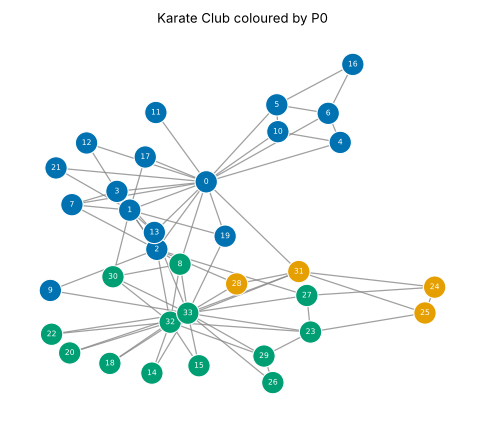

In [3]:
P0 = detect_communities(G, "louvain", seed=42)
print("P0 sizes:", sorted(map(len, P0), reverse=True), " Q0 =", round(modularity_fixed_partition(G, P0), 4))
from src.visualization.graph_visualization import fixed_layout, draw_graph
fig, ax = plt.subplots(figsize=(6, 5)); draw_graph(ax, G, fixed_layout(G, 42), P0, "Karate Club coloured by P0", node_size=260); plt.show()

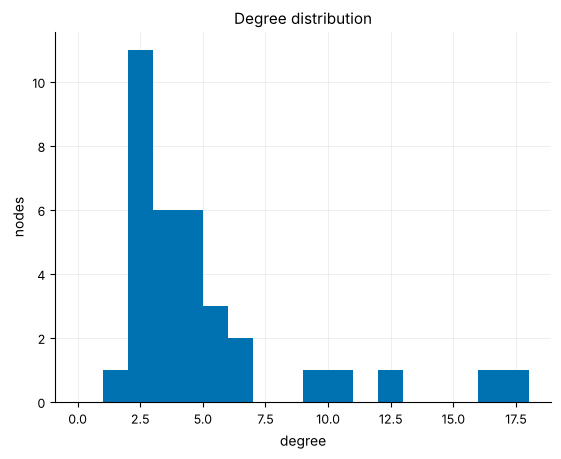

In [4]:
from src.evaluation.graph_metrics import degree_sequence
d = degree_sequence(G); plt.hist(d, bins=range(0, 19), color="#0072B2"); plt.xlabel("degree"); plt.ylabel("nodes"); plt.title("Degree distribution"); plt.show()